# Chicago Crime Domestic Classification

This notebook trains a chronological machine-learning classifier on the Chicago Crimes dataset.

**Task:** predict the existing `Domestic` label (`True` / `False`) for incidents from 2025, using earlier records for training and validation.

This is **not** the same target as the NCRB project's five-class district-year violent-crime burden. An 80% accuracy target is a goal, not a guarantee; use the locked 2025 test metrics as the honest result.

## Time split
- Train: 2023 through 30 June 2024
- Validation: 1 July through 31 December 2024
- Test: 2025

The model excludes columns such as `Description`, `IUCR`, `FBI Code`, `Arrest`, identifiers, coordinates, and update timestamps to reduce target leakage and avoid using potentially unavailable or answer-revealing fields.

## 1. Install required packages

Run this cell once in the VS Code notebook kernel if the packages are missing.

In [6]:
%pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Set the CSV path

Put the CSV in the same folder as this notebook and the Python script, or change `CSV_PATH` to its full path.

In [7]:

from pathlib import Path

search_locations = [
    Path(r"C:\Users\aru12\OneDrive\Desktop\capstone project"),
    Path(r"C:\Users\aru12\Downloads"),
]

csv_files = []

for folder in search_locations:
    if folder.exists():
        csv_files.extend(
            folder.rglob("Crimes_-_2001_to_Present_20260902*.csv")
        )

for file in csv_files:
    print(file)


C:\Users\aru12\OneDrive\Desktop\capstone project\data\raw\Crimes_-_2001_to_Present_20260902.csv
C:\Users\aru12\Downloads\Crimes_-_2001_to_Present_20260902.csv


In [8]:

from pathlib import Path

CSV_PATH = Path(
    r"C:\Users\aru12\OneDrive\Desktop\capstone project\data\raw\Crimes_-_2001_to_Present_20260902.csv"
)

print("CSV exists:", CSV_PATH.exists())


CSV exists: True


## 3. Load the helper functions

The full reusable implementation is in `chicago_domestic_classifier.py`. Keep that file in the same folder as this notebook.

In [10]:

from pathlib import Path
import importlib.util

# Your notebook is inside the notebooks folder
PROJECT_ROOT = Path.cwd().parent

# Python file is in the main capstone project folder
SCRIPT_PATH = PROJECT_ROOT / "chicago_domestic_classifier.py"

print("Project folder:", PROJECT_ROOT)
print("Python file:", SCRIPT_PATH)
print("File exists:", SCRIPT_PATH.exists())

if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f"Python file not found at: {SCRIPT_PATH}"
    )

spec = importlib.util.spec_from_file_location(
    "chicago_domestic_classifier", SCRIPT_PATH
)

classifier = importlib.util.module_from_spec(spec)
spec.loader.exec_module(classifier)

print("Python file imported successfully!")
print("Features:", classifier.FEATURES)


Project folder: c:\Users\aru12\OneDrive\Desktop\capstone project
Python file: c:\Users\aru12\OneDrive\Desktop\capstone project\chicago_domestic_classifier.py
File exists: True
Python file imported successfully!
Features: ['Primary Type', 'Location Description', 'Beat', 'Hour', 'Month', 'DayOfWeek', 'IsWeekend']


In [11]:

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

search_locations = [
    PROJECT_ROOT,
    Path.home() / "Downloads",
]

csv_files = []

for folder in search_locations:
    if folder.exists():
        csv_files.extend(
            folder.rglob(
                "Crimes_-_2001_to_Present_20260902*.csv"
            )
        )

# Remove duplicate paths
csv_files = list(dict.fromkeys(csv_files))

if csv_files:
    CSV_PATH = csv_files[0]
    print("CSV found:", CSV_PATH)
else:
    raise FileNotFoundError(
        "CSV not found in the project or Downloads folder. "
        "Locate the CSV and add its path to CSV_PATH."
    )

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "chicago_domestic"


CSV found: c:\Users\aru12\OneDrive\Desktop\capstone project\data\raw\Crimes_-_2001_to_Present_20260902.csv


## 4. Load and inspect the 2023–2025 records

This reads the large CSV in chunks to reduce memory usage.

In [12]:
data = classifier.load_chicago_data(str(CSV_PATH))
display(data.head())
display(data[classifier.TARGET].value_counts(normalize=True).rename("proportion").to_frame())

Reading c:\Users\aru12\OneDrive\Desktop\capstone project\data\raw\Crimes_-_2001_to_Present_20260902.csv in chunks; keeping years 2023-2025...
Rows retained: 759,290
Date range: 2023-01-01 14:36:00 to 2025-12-31 14:30:00
Domestic positive rate: 18.402%


,Date,Primary Type,Location Description,Beat,Hour,Month,DayOfWeek,IsWeekend,Domestic
0,2023-01-01 14:36:00,OTHER OFFENSE,STREET,2413,14,1,6,1,0
1,2023-01-01 14:38:00,ASSAULT,STREET,432,14,1,6,1,0
2,2023-01-01 14:39:00,CRIMINAL DAMAGE,ALLEY,1723,14,1,6,1,0
3,2023-01-01 14:40:00,DECEPTIVE PRACTICE,Unknown,1424,14,1,6,1,0
4,2023-01-01 14:45:00,CRIMINAL DAMAGE,APARTMENT,1011,14,1,6,1,0


,proportion
Domestic,
0,0.815979
1,0.184021


## 5. Create chronological train, validation, and test sets

In [13]:
train, val, test = classifier.chronological_split(data)

print("Train target distribution:")
display(train[classifier.TARGET].value_counts(normalize=True).rename("proportion").to_frame())
print("Validation target distribution:")
display(val[classifier.TARGET].value_counts(normalize=True).rename("proportion").to_frame())
print("Test target distribution:")
display(test[classifier.TARGET].value_counts(normalize=True).rename("proportion").to_frame())


Chronological split
Train (through 2024-06-30): 389,856
Validation (2024-07-01 to 2024-12-31): 131,995
Test (2025): 237,439
Train target distribution:


,proportion
Domestic,
0,0.818859
1,0.181141


Validation target distribution:


,proportion
Domestic,
0,0.818872
1,0.181128


Test target distribution:


,proportion
Domestic,
0,0.809644
1,0.190356


## 6. Train the model

The model is a HistGradientBoosting classifier. Categorical features are encoded using an encoder that can handle previously unseen categories.

In [14]:
X_train, y_train = train[classifier.FEATURES], train[classifier.TARGET]
X_val, y_val = val[classifier.FEATURES], val[classifier.TARGET]
X_test, y_test = test[classifier.FEATURES], test[classifier.TARGET]

model = classifier.make_model()
model.fit(X_train, y_train)
print("Training complete.")

Training complete.


## 7. Select a threshold on validation only

Threshold selection uses validation data, not the 2025 test labels.

In [15]:
val_prob = model.predict_proba(X_val)[:, 1]
threshold = classifier.choose_threshold(y_val.to_numpy(), val_prob)
print("Selected threshold:", threshold)


Validation-selected threshold: 0.20 (balanced accuracy=0.8406)
Selected threshold: 0.2


## 8. Final evaluation on the 2025 test set

Report accuracy alongside balanced accuracy, precision, recall, F1 and ROC-AUC. If accuracy is near or above 80%, report the measured value; do not claim a target result before running the experiment.

In [16]:
test_prob = model.predict_proba(X_test)[:, 1]
test_metrics, test_pred = classifier.evaluate_split(
    "TEST (2025)", y_test.to_numpy(), test_prob, threshold
)
default_metrics, default_pred = classifier.evaluate_split(
    "TEST (2025), default threshold 0.50",
    y_test.to_numpy(), test_prob, 0.5
)


TEST (2025) metrics
threshold: 0.2000
accuracy: 0.8331
balanced_accuracy: 0.8349
precision_domestic: 0.5397
recall_domestic: 0.8378
f1_domestic: 0.6565
roc_auc: 0.9137

Classification report:
              precision    recall  f1-score   support

Non-Domestic       0.96      0.83      0.89    192241
    Domestic       0.54      0.84      0.66     45198

    accuracy                           0.83    237439
   macro avg       0.75      0.83      0.77    237439
weighted avg       0.88      0.83      0.85    237439

Confusion matrix (rows=actual, columns=predicted; labels 0,1):
[[159947  32294]
 [  7330  37868]]

TEST (2025), default threshold 0.50 metrics
threshold: 0.5000
accuracy: 0.8792
balanced_accuracy: 0.7580
precision_domestic: 0.7406
recall_domestic: 0.5624
f1_domestic: 0.6393
roc_auc: 0.9137

Classification report:
              precision    recall  f1-score   support

Non-Domestic       0.90      0.95      0.93    192241
    Domestic       0.74      0.56      0.64     45198

 

## 9. Save metrics, predictions, and confusion matrix

In [17]:
import json
import pandas as pd
from sklearn.metrics import confusion_matrix

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
metrics = {
    "target": classifier.TARGET,
    "features": classifier.FEATURES,
    "train_period": "2023-01-01 through 2024-06-30",
    "validation_period": "2024-07-01 through 2024-12-31",
    "test_period": "2025",
    "validation_selected_threshold": threshold,
    "test_metrics_validation_threshold": test_metrics,
    "test_metrics_default_threshold": default_metrics,
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

test_output = test[["Date"] + classifier.FEATURES + [classifier.TARGET]].copy()
test_output["Domestic_Probability"] = test_prob
test_output["Predicted_Domestic"] = test_pred.astype("int8")
test_output.to_csv(OUTPUT_DIR / "test_predictions_2025.csv", index=False)

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
pd.DataFrame(
    cm,
    index=["Actual_Non_Domestic", "Actual_Domestic"],
    columns=["Predicted_Non_Domestic", "Predicted_Domestic"],
).to_csv(OUTPUT_DIR / "confusion_matrix_2025.csv")

print("Saved files in:", OUTPUT_DIR.resolve())
print("Metrics:", OUTPUT_DIR / "metrics.json")
print("Predictions:", OUTPUT_DIR / "test_predictions_2025.csv")
print("Confusion matrix:", OUTPUT_DIR / "confusion_matrix_2025.csv")

Saved files in: C:\Users\aru12\OneDrive\Desktop\capstone project\outputs\chicago_domestic
Metrics: c:\Users\aru12\OneDrive\Desktop\capstone project\outputs\chicago_domestic\metrics.json
Predictions: c:\Users\aru12\OneDrive\Desktop\capstone project\outputs\chicago_domestic\test_predictions_2025.csv
Confusion matrix: c:\Users\aru12\OneDrive\Desktop\capstone project\outputs\chicago_domestic\confusion_matrix_2025.csv


## 10. Interpretation and limitations

- The target is the existing `Domestic` label, not a five-class crime-burden score.
- This is an incident-level classification experiment, not district-year forecasting.
- The model may not reach 80%; the test result must be reported honestly.
- Accuracy alone can be misleading if Domestic and Non-Domestic labels are imbalanced.
- A strong score does not prove causal relationships or operational usefulness.
- The CSV includes records through different reporting/update periods; this script uses incident dates and excludes `Updated On`.
- The feature set is deliberately limited to `Primary Type`, `Location Description`, `Beat`, and time-derived features.

In [18]:

# MODEL COMPARISON: CHICAGO DOMESTIC CLASSIFICATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Optional XGBoost
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

# Use the same feature definitions as the existing notebook
CAT_FEATURES = classifier.CAT_FEATURES
NUM_FEATURES = classifier.NUM_FEATURES
FEATURES = classifier.FEATURES

X_train, y_train = train[FEATURES], train["Domestic"]
X_val, y_val = val[FEATURES], val["Domestic"]
X_test, y_test = test[FEATURES], test["Domestic"]

# Shared preprocessing ensures a fair comparison
preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), CAT_FEATURES),
    ("num", SimpleImputer(strategy="median"), NUM_FEATURES)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

if XGBOOST_AVAILABLE:
    models["XGBoost"] = XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    pipe = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    # Use validation data to choose a classification threshold
    val_prob = pipe.predict_proba(X_val)[:, 1]
    threshold = classifier.choose_threshold(
        y_val.to_numpy(), val_prob
    )

    # Final evaluation on the same held-out 2025 test set
    test_prob = pipe.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, test_pred
        ),
        "Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, test_prob)
    })

    fitted_models[name] = pipe

comparison_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Balanced Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)

# Save comparison results
comparison_path = OUTPUT_DIR / "model_comparison_2025.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)


Training Logistic Regression...

Validation-selected threshold: 0.48 (balanced accuracy=0.7077)
Training Random Forest...

Validation-selected threshold: 0.37 (balanced accuracy=0.8336)
Training HistGradientBoosting...

Validation-selected threshold: 0.20 (balanced accuracy=0.8408)
Training XGBoost...

Validation-selected threshold: 0.20 (balanced accuracy=0.8400)


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.20,83.37%,83.48%,54.08%,83.65%,65.69%,0.9139
1,HistGradientBoosting,0.20,83.33%,83.49%,54.01%,83.76%,65.67%,0.9136
2,Random Forest,0.37,81.44%,82.79%,50.75%,84.97%,63.55%,0.9068
3,Logistic Regression,0.48,64.91%,69.37%,32.24%,76.57%,45.38%,0.7528


Comparison saved to: c:\Users\aru12\OneDrive\Desktop\capstone project\outputs\chicago_domestic\model_comparison_2025.csv


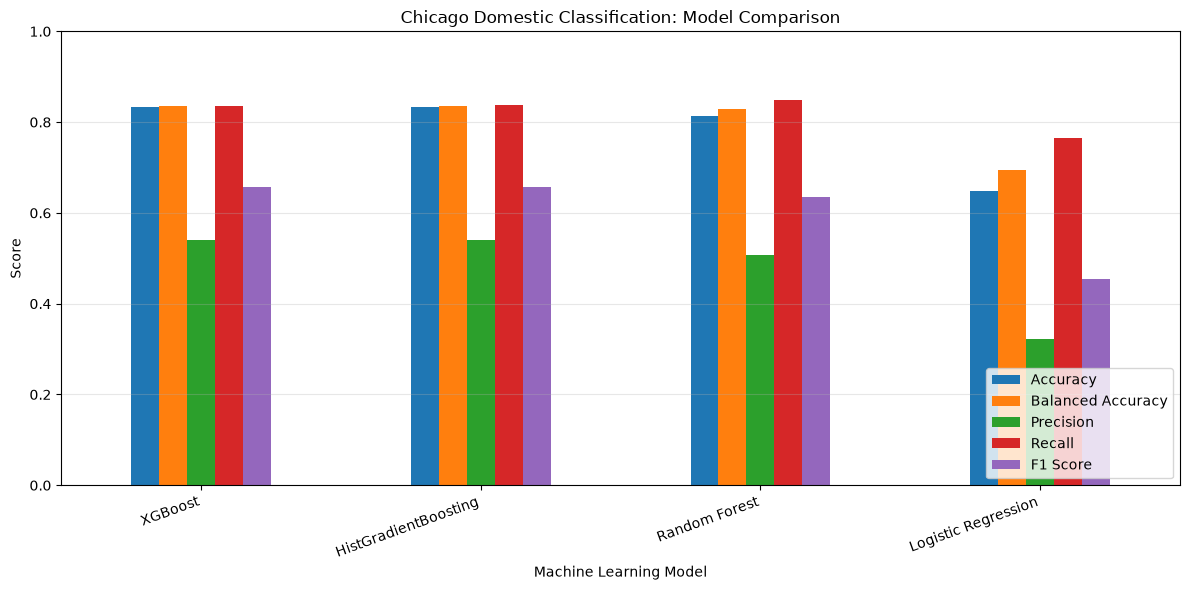

In [19]:

# VISUAL COMPARISON OF MODELS

metrics_to_plot = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

comparison_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Chicago Domestic Classification: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


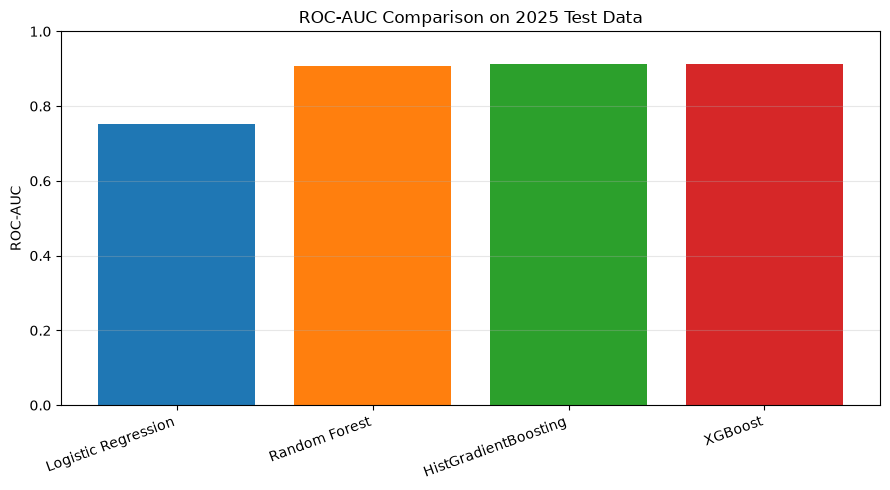

In [20]:

# ROC-AUC COMPARISON

plt.figure(figsize=(9, 5))

for name, pipe in fitted_models.items():
    probabilities = pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)

    plt.bar(name, auc, label=f"{name}: {auc:.3f}")

plt.title("ROC-AUC Comparison on 2025 Test Data")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
